# Giai đoạn 1 – Baseline

Mục tiêu: xây dựng các mô hình đơn giản làm **mốc so sánh** cho các giai đoạn sau, và kiểm tra kết quả dự đoán.

- Dữ liệu: `data/processed/train.csv`, `val.csv`, `test.csv` (tạo bởi `python -m src.data_prep`, chia theo thời gian đặt hàng).
- Quy trình: fit trên **train**, chọn baseline tốt nhất trên **val**, báo cáo trên **test**.
- Metric chính: **MAE** (ngày). Thêm RMSE, R² và tỉ lệ đơn dự đoán lệch ≤ 3 ngày.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.utils import load_config, regression_metrics, resolve

pd.set_option("display.width", 200)
cfg = load_config()
TARGET = cfg["features"]["target"]
NUMERIC = cfg["features"]["numeric"]
PROC = resolve(cfg["paths"]["processed_dir"])
OUT = resolve(cfg["paths"]["model_path"]).parent

## 1. Đọc dữ liệu đã tiền xử lý

In [2]:
splits = {s: pd.read_csv(PROC / f"{s}.csv", parse_dates=["order_purchase_timestamp"])
          for s in ("train", "val", "test")}
train, val, test = splits["train"], splits["val"], splits["test"]

pd.DataFrame({s: {"rows": len(d),
                  "from": d.order_purchase_timestamp.min().date(),
                  "to": d.order_purchase_timestamp.max().date(),
                  "mean_days": round(d[TARGET].mean(), 2),
                  "median_days": round(d[TARGET].median(), 2)}
              for s, d in splits.items()}).T

,rows,from,to,mean_days,median_days
train,67191,2016-10-03,2018-04-16,13.41,11.38
val,14398,2018-04-16,2018-06-21,10.74,8.9
test,14398,2018-06-21,2018-08-29,8.3,7.22


## 2. Định nghĩa các baseline

| | Baseline | Ý tưởng |
|---|---|---|
| B0 | Trung bình toàn cục | Luôn đoán trung bình của train |
| B1 | Median toàn cục | Luôn đoán median của train (tối ưu MAE) |
| B2 | Ước tính Olist | `estimated_days` Olist báo cho khách |
| B3 | Ước tính Olist × hệ số | Hiệu chỉnh `estimated_days` bằng tỉ lệ median học từ train |
| B4 | Median theo bang khách | Nhóm theo `customer_state` |
| B5 | Median theo tuyến | Nhóm theo (`seller_state`, `customer_state`), fallback về bang rồi toàn cục |
| B6 | Hồi quy theo khoảng cách | Linear regression trên `distance_km` |
| B7 | Hồi quy tuyến tính | Linear regression trên toàn bộ feature số |

In [3]:
class GroupMedian:
    """Median theo nhóm; nhóm < min_count mẫu hoặc chưa thấy -> fallback về nhóm thô hơn."""

    def __init__(self, keys, min_count=20):
        self.keys, self.min_count = list(keys), min_count

    def fit(self, df, y):
        y = np.asarray(y)
        self.global_ = float(np.median(y))
        g = df[self.keys].assign(_y=y).groupby(self.keys)["_y"].agg(["median", "count"])
        self.table_ = g.loc[g["count"] >= self.min_count, "median"]
        self.fallback_ = GroupMedian(self.keys[1:], self.min_count).fit(df, y) if len(self.keys) > 1 else None
        return self

    def predict(self, df):
        idx = pd.MultiIndex.from_frame(df[self.keys]) if len(self.keys) > 1 else pd.Index(df[self.keys[0]])
        pred = pd.Series(self.table_.reindex(idx).to_numpy(), index=df.index)
        fb = self.fallback_.predict(df) if self.fallback_ else np.full(len(df), self.global_)
        return pred.fillna(pd.Series(fb, index=df.index)).to_numpy()

In [4]:
y_train = train[TARGET].to_numpy()
mean, median = y_train.mean(), np.median(y_train)
ratio = np.median(y_train / train["estimated_days"].clip(lower=1))
print(f"mean={mean:.2f}  median={median:.2f}  hệ số hiệu chỉnh Olist={ratio:.3f}")

by_state = GroupMedian(["customer_state"]).fit(train, y_train)
by_route = GroupMedian(["seller_state", "customer_state"]).fit(train, y_train)
lin_d = LinearRegression().fit(train[["distance_km"]], y_train)
lin = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()).fit(train[NUMERIC], y_train)

models = {
    "B0_global_mean":           lambda d: np.full(len(d), mean),
    "B1_global_median":         lambda d: np.full(len(d), median),
    "B2_olist_estimate":        lambda d: d["estimated_days"].fillna(median).to_numpy(),
    "B3_olist_estimate_scaled": lambda d: (d["estimated_days"].fillna(median) * ratio).to_numpy(),
    "B4_median_by_cust_state":  by_state.predict,
    "B5_median_by_route":       by_route.predict,
    "B6_linear_distance":       lambda d: lin_d.predict(d[["distance_km"]]),
    "B7_linear_regression":     lambda d: lin.predict(d[NUMERIC]),
}

mean=13.41  median=11.38  hệ số hiệu chỉnh Olist=0.472


## 3. Đánh giá trên train / val / test

In [5]:
rows = [{"model": n, "split": s, **regression_metrics(d[TARGET], f(d))}
        for n, f in models.items() for s, d in splits.items()]
table = pd.DataFrame(rows).pivot(index="model", columns="split", values=["MAE", "RMSE", "R2", "within_3_days"])
table = table.reindex(columns=["train", "val", "test"], level=1)
table.round(3)

MAE                    RMSE                     R2               within_3_days              
split                      train     val    test   train     val    test  train    val   test         train    val   test
model                                                                                                                    
B0_global_mean             6.385   6.334   6.366   8.555   7.689   7.232  0.000 -0.137 -0.995         0.290  0.224  0.178
B1_global_median           6.174   5.567   4.975   8.791   7.241   5.978 -0.056 -0.008 -0.363         0.340  0.294  0.282
B2_olist_estimate         12.468  14.870  10.666  14.345  17.166  13.023 -1.812 -4.666 -5.468         0.069  0.052  0.141
B3_olist_estimate_scaled   5.388   5.137   3.526   8.035   6.917   4.981  0.118  0.080  0.054         0.429  0.385  0.558
B4_median_by_cust_state    5.358   4.590   4.512   7.830   6.151   5.548  0.162  0.273 -0.174         0.409  0.394  0.350
B5_median_by_route         5.156   4.454   4.422   7.615   6.000   5.486  0.208  0.308 -0.148         0.428  0.405  0.362
B6_linear_distance         5.618   5.392   5.828   7.739   6.611   6.676  0.182  0.160 -0.700         0.338  0.265  0.187
B7_linear_regression       5.228   5.193   4.823   7.328   6.493   5.922  0.266  0.189 -0.337         0.386  0.316  0.350

In [6]:
best = table[("MAE", "val")].idxmin()      # chọn theo val, không nhìn test
print(f"Baseline tốt nhất theo MAE val: {best}")
print(f"  Test MAE  = {table.loc[best, ('MAE', 'test')]:.3f} ngày")
print(f"  Test RMSE = {table.loc[best, ('RMSE', 'test')]:.3f} ngày")
print(f"  Lệch ≤ 3 ngày: {table.loc[best, ('within_3_days', 'test')]:.1%}")

Baseline tốt nhất theo MAE val: B5_median_by_route
  Test MAE  = 4.422 ngày
  Test RMSE = 5.486 ngày
  Lệch ≤ 3 ngày: 36.2%


## 4. Kiểm tra kết quả dự đoán trên test

In [7]:
preds = {n: f(test) for n, f in models.items()}
sample = test[["order_id", "customer_state", "seller_state", "distance_km", "estimated_days", TARGET]].copy()
for n, p in preds.items():
    sample[n] = p
sample[["order_id", "customer_state", "seller_state", TARGET,
        "B2_olist_estimate", "B3_olist_estimate_scaled", "B5_median_by_route"]].head(10).round(2)

,order_id,customer_state,seller_state,delivery_days,B2_olist_estimate,B3_olist_estimate_scaled,B5_median_by_route
0,fe1db39ee392d14b9d8b00c17e02023f,SP,SP,6.33,24.45,11.54,7.20
1,96f2c3b92eb876c71d228377a641c6e2,SP,PR,4.12,31.45,14.85,10.41
2,0933fe2645eef2cb8ca4aeadb9d3834b,PR,SP,8.39,24.44,11.54,12.21
3,aa57296ceb0b170f4823d71a06a43037,SP,RJ,7.28,35.44,16.73,11.14
4,1782119bc21f8f920e4557c56091a68a,RJ,SP,14.32,39.44,18.62,13.98
5,0166ae6ff6d450bbac3eb4ed2885c0f8,SP,SP,2.01,19.44,9.18,7.20
6,c6b0115592f584f15795ca244bd83fb2,RJ,PR,6.04,52.43,24.76,15.25
7,c6aae003b7c6c4c197112467858aa37b,MG,SP,6.22,25.43,12.01,11.82
8,39b1f85275dd200066b0ec1a4b5e09c3,PR,MG,14.09,28.43,13.42,12.22
9,ba7243ecb3b63c80579ba1d4c34e277c,PR,MG,13.22,28.43,13.42,12.22


Độ lệch (bias) = trung bình (dự đoán − thực tế). Bias dương nghĩa là mô hình đoán dư.

In [8]:
y = test[TARGET].to_numpy()
pd.DataFrame({n: {"bias": np.mean(p - y), "MAE": np.mean(np.abs(p - y)),
                  "đoán dư (%)": np.mean(p > y) * 100}
              for n, p in preds.items()}).T.sort_values("MAE").round(2)

,bias,MAE,đoán dư (%)
B3_olist_estimate_scaled,0.41,3.53,56.40
B5_median_by_route,2.85,4.42,81.05
B4_median_by_cust_state,2.93,4.51,81.77
B7_linear_regression,3.55,4.82,84.10
B1_global_median,3.09,4.98,80.89
B6_linear_distance,4.81,5.83,89.47
B0_global_mean,5.11,6.37,88.01
B2_olist_estimate,10.15,10.67,93.48


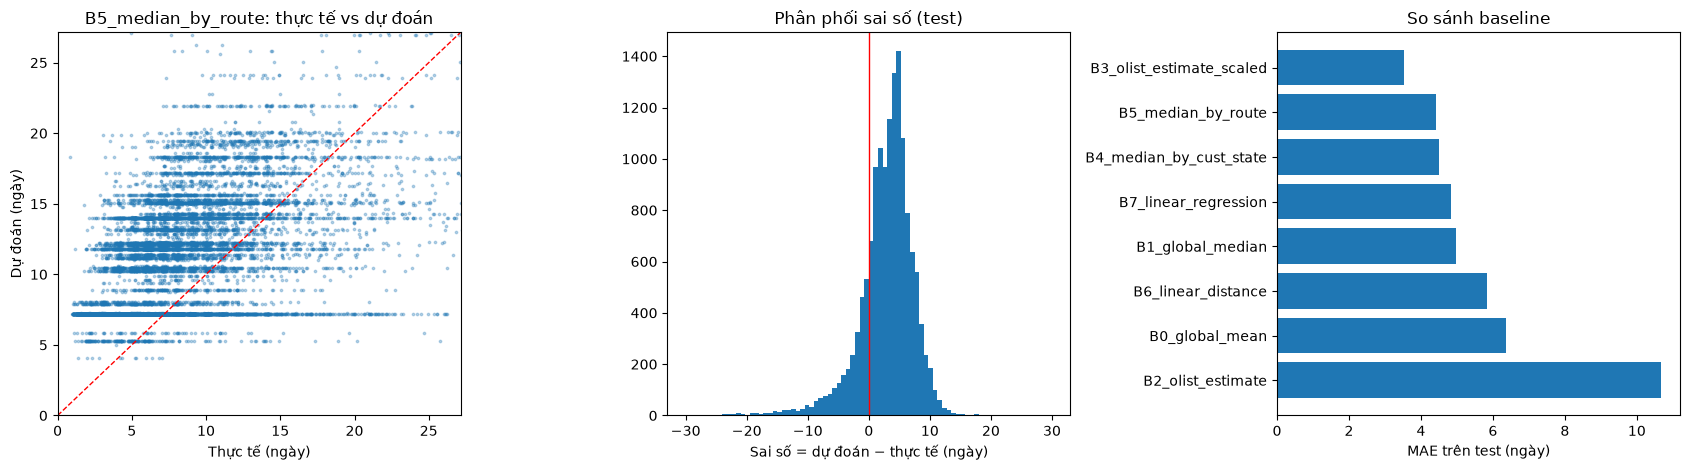

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
p = preds[best]
lim = np.percentile(y, 99)
ax[0].scatter(y, p, s=3, alpha=.3)
ax[0].plot([0, lim], [0, lim], "r--", lw=1)
ax[0].set(xlim=(0, lim), ylim=(0, lim), xlabel="Thực tế (ngày)", ylabel="Dự đoán (ngày)", title=f"{best}: thực tế vs dự đoán")
ax[1].hist(p - y, bins=80, range=(-30, 30))
ax[1].axvline(0, color="r", lw=1)
ax[1].set(xlabel="Sai số = dự đoán − thực tế (ngày)", title="Phân phối sai số (test)")
mae = table[("MAE", "test")].sort_values()
ax[2].barh(mae.index, mae.values)
ax[2].invert_yaxis()
ax[2].set(xlabel="MAE trên test (ngày)", title="So sánh baseline")
plt.tight_layout(); plt.show()

### Thời gian giao thay đổi theo thời gian

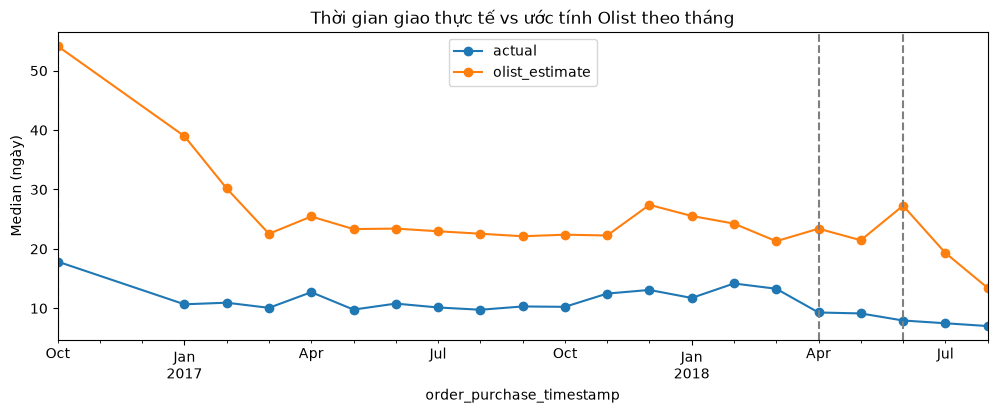

In [10]:
all_ = pd.concat([d.assign(split=s) for s, d in splits.items()])
m = all_.groupby(all_.order_purchase_timestamp.dt.to_period("M")).agg(
    actual=(TARGET, "median"), olist_estimate=("estimated_days", "median"), n=(TARGET, "size"))
m = m[m["n"] >= 100]
ax = m[["actual", "olist_estimate"]].plot(figsize=(12, 4), marker="o")
for s, d in splits.items():
    ax.axvline(pd.Period(d.order_purchase_timestamp.min(), "M"), ls="--", c="gray")
ax.set(ylabel="Median (ngày)", title="Thời gian giao thực tế vs ước tính Olist theo tháng")
plt.show()

## 5. Lưu kết quả

In [11]:
OUT.mkdir(parents=True, exist_ok=True)
flat = table.copy(); flat.columns = [f"{a}_{b}" for a, b in flat.columns]
flat.round(4).to_csv(OUT / "baseline_metrics.csv")
sample.round(2).to_csv(OUT / "baseline_predictions.csv", index=False)
print("Saved:", OUT / "baseline_metrics.csv", "|", OUT / "baseline_predictions.csv")

Saved: /home/zaboo/PycharmProjects/ML/MachineLearning/models/baseline_metrics.csv | /home/zaboo/PycharmProjects/ML/MachineLearning/models/baseline_predictions.csv


## 6. Nhận xét

- **Baseline chọn theo val: B5 – median theo tuyến** (test MAE ≈ 4.4 ngày, ~36% đơn lệch ≤ 3 ngày).
- **Ước tính của Olist dư rất nhiều** (B2 gấp 2–3 lần thực tế), nhưng nhân hệ số (B3) lại cho MAE test thấp nhất ≈ 3.5 ngày, vì Olist cũng rút ngắn ước tính theo thời gian.
- **Thời gian giao giảm dần theo thời gian** (median train ≈ 11.4 → val ≈ 8.9 → test ≈ 7.2 ngày), nên các baseline học từ dữ liệu cũ đều **đoán dư** (bias dương) và R² trên test âm.
- Baseline theo nhóm chỉ ra một vài giá trị cố định (các dải ngang trên biểu đồ) → không phân biệt được đơn nhanh/chậm trong cùng tuyến.

**Mốc cần vượt ở các giai đoạn sau:** test MAE 4.42 (B5) và 3.53 (B3).